**Programmer: python_scripts (Abhijith Warrier)**

**🔬 Python Code Lab — *How Expensive Are Python Exceptions?***

Python exceptions provide a structured way to handle unexpected conditions, but raising and catching them can introduce performance overhead.

This experiment uses `timeit` to compare normal execution, successful `try/except` blocks, and frequently raised exceptions to understand their actual performance cost.

---

## ❓ Question

How much performance overhead does exception handling introduce in Python?

Consider three situations:

- **Normal Execution:** Code runs without exception handling.
- **Successful Try/Except:** Code executes inside a `try/except` block without raising an exception.
- **Raised Exception:** An exception is raised and handled during execution.

We'll benchmark these scenarios to determine whether simply using `try/except` is expensive or whether the actual cost comes from raising exceptions.

---

## 🧪 Experiment Setup

We'll use Python's built-in `timeit` module to benchmark different exception-handling scenarios.

Our experiments will measure:

- Normal function execution.
- Successful execution inside a `try/except` block.
- Raising and catching an exception.
- Exception-heavy execution across different failure rates.

Each benchmark will run multiple times, and we'll calculate the average time per operation using the fastest recorded repetition. The results will be displayed in microseconds (µs).

**Note:** Modern CPython versions, particularly Python 3.11 and later, optimise exception handling when no exception is raised. The exact performance characteristics depend on the Python version and implementation.

In [1]:
# Import timeit for measuring execution time
import timeit
# Import random for generating reproducible test workloads
import random

# Configure benchmark iterations
iterations = 100_000
# Number of benchmark repetitions
repeats = 5
# Define failure rates for the final experiment
failure_rates = [0, 1, 10, 50, 100]

# Use a fixed seed for reproducible workloads
random.seed(42)

---

## ▶️ Experiment 1 — Normal Function Execution

We'll begin with a simple function that performs an arithmetic operation. This establishes a baseline for measuring execution time without exception handling.

Later experiments will use the same arithmetic operation so we can compare the additional overhead introduced by exception handling.

In [2]:
def normal_execution():
    """Execute a simple operation without exception handling."""
    value = 10
    return value + 5


# Verify the function output
print("Normal execution:", normal_execution())

Normal execution: 15


---

## ▶️ Experiment 2 — Exception Handling Without Errors

Next, we'll perform the same operation inside a `try/except` block. No exception will be raised during execution. This allows us to investigate whether the presence of a `try/except` block introduces significant overhead when everything works normally.

On modern CPython versions, successful exception-handling paths are designed to be relatively inexpensive.

In [3]:
def successful_try_except():
    """Execute the same operation inside a try/except block."""
    try:
        value = 10
        return value + 5
    except ValueError:
        return None


# Verify the function output
print("Successful try/except:", successful_try_except())

Successful try/except: 15


---

## ▶️ Experiment 3 — Raising and Catching an Exception

Now we'll deliberately raise an exception and catch it immediately. Unlike the previous experiment, Python must create or prepare the exception, transfer control to the exception handler, and manage the exception state. We'll compare this with normal execution to measure the additional cost of an actual exception.

The goal is to understand why exceptions are generally better suited for exceptional conditions rather than frequently occurring control-flow decisions.

In [4]:
def raised_exception():
    """Raise and catch an exception during execution."""
    try:
        raise ValueError("Something went wrong")
    except ValueError:
        return None


# Verify the function output
print("Raised exception:", raised_exception())

Raised exception: None


---

## ▶️ Experiment 4 — Measuring Execution Time

We'll now benchmark all three functions using `timeit.repeat()`. Each function will execute 100,000 times per repetition.

We'll select the fastest repetition and calculate the average execution time per function call.Using the fastest repetition helps reduce the influence of temporary system interruptions, although benchmark results can still vary. Because these functions perform very little work, the measurements also include Python function-call overhead.

In [5]:
def benchmark_function(func):
    """Measure average execution time per function call."""

    # Repeat the benchmark multiple times
    timings = timeit.repeat(
        func,
        number=iterations,
        repeat=repeats,
    )

    # Select the fastest recorded repetition
    best_time = min(timings)

    # Convert seconds per operation into microseconds
    return (best_time / iterations) * 1_000_000


# Benchmark each scenario
normal_time = benchmark_function(normal_execution)
try_except_time = benchmark_function(successful_try_except)
exception_time = benchmark_function(raised_exception)


# Display the measurements
print("Exception Handling Benchmark\n")
print(f"Normal Execution:      {normal_time:.4f} µs")
print(f"Successful Try/Except: {try_except_time:.4f} µs")
print(f"Raised Exception:      {exception_time:.4f} µs")

Exception Handling Benchmark

Normal Execution:      0.0266 µs
Successful Try/Except: 0.0258 µs
Raised Exception:      0.1122 µs


---

## 📊 Results — Exception Handling Overhead

Let's compare the measured execution times and calculate their relative differences.

We'll use normal execution as the baseline. A ratio greater than `1x` indicates that the corresponding operation took longer than normal execution. The exact values are generated when the notebook runs.

We expect successful `try/except` execution to be relatively close to normal execution on modern CPython versions, while raising and catching exceptions will generally be more expensive.

In [6]:
# Calculate relative execution costs
try_except_ratio = try_except_time / normal_time
exception_ratio = exception_time / normal_time

print("EXCEPTION HANDLING — PERFORMANCE COMPARISON\n")
print(
    f"{'Scenario':<25}"
    f"{'Time (µs)':>15}"
    f"{'Relative Cost':>18}"
)
print("-" * 58)

results = [
    ("Normal Execution", normal_time),
    ("Successful Try/Except", try_except_time),
    ("Raised Exception", exception_time),
]

for scenario, execution_time in results:
    ratio = execution_time / normal_time

    print(
        f"{scenario:<25}"
        f"{execution_time:>15.4f}"
        f"{ratio:>17.2f}x"
    )

EXCEPTION HANDLING — PERFORMANCE COMPARISON

Scenario                       Time (µs)     Relative Cost
----------------------------------------------------------
Normal Execution                  0.0266             1.00x
Successful Try/Except             0.0258             0.97x
Raised Exception                  0.1122             4.22x


---

## ▶️ Experiment 5 — Does Exception Frequency Matter?

So far, we've compared individual operations. But real applications don't necessarily raise exceptions on every request or operation. Some operations succeed most of the time, while others may encounter failures frequently.

We'll simulate workloads with different failure rates:

- 0% — No exceptions.
- 1% — Rare exceptions.
- 10% — Occasional exceptions.
- 50% — Frequent exceptions.
- 100% — Every operation raises an exception.

We'll prepare the workloads before timing them so random number generation doesn't become part of the benchmark. This experiment will help us observe how execution time changes as exceptions become more frequent.

In [7]:
# Number of operations in each workload
workload_size = 10_000
# Store workloads for different failure rates
workloads = {}

for rate in failure_rates:
    # Calculate the number of failing operations
    failures = int(workload_size * rate / 100)
    # Create a workload containing successes and failures
    workload = [False] * (workload_size - failures)
    workload += [True] * failures
    # Shuffle to distribute failures across the workload
    random.shuffle(workload)
    workloads[rate] = workload


# Display the configured workloads
for rate, workload in workloads.items():
    print(
        f"Failure Rate: {rate:>3}% | "
        f"Operations: {len(workload):,} | "
        f"Failures: {sum(workload):,}"
    )

Failure Rate:   0% | Operations: 10,000 | Failures: 0
Failure Rate:   1% | Operations: 10,000 | Failures: 100
Failure Rate:  10% | Operations: 10,000 | Failures: 1,000
Failure Rate:  50% | Operations: 10,000 | Failures: 5,000
Failure Rate: 100% | Operations: 10,000 | Failures: 10,000


---

## ▶️ Experiment 6 — Measuring Exception-Heavy Execution

We'll process each workload using the same function. Successful operations perform a simple calculation, while failing operations raise and catch a `ValueError`.

The function will return the number of successfully completed operations. We'll measure the total execution time for each workload and calculate the average time per operation. Because the workloads contain the same number of operations, we can compare how increasing exception frequency affects execution time.

In [8]:
def process_workload(workload):
    """Process operations with controlled exception frequency."""
    successful_operations = 0

    for should_fail in workload:
        try:
            if should_fail:
                raise ValueError("Operation failed")
            # Simulate a successful operation
            result = 10 + 5
            successful_operations += 1
        except ValueError:
            pass

    return successful_operations


def benchmark_workload(workload):
    """Measure average execution time per workload operation."""

    # Benchmark the complete workload
    timings = timeit.repeat(
        lambda: process_workload(workload),
        number=100,
        repeat=repeats,
    )
    best_time = min(timings)
    # Calculate microseconds per operation
    total_operations = len(workload) * 100

    return (best_time / total_operations) * 1_000_000


# Benchmark workloads with different failure rates
frequency_results = []
for rate, workload in workloads.items():
    execution_time = benchmark_workload(workload)
    frequency_results.append(
        (rate, execution_time)
    )


print("EXCEPTION FREQUENCY BENCHMARK\n")
print(
    f"{'Failure Rate':>15}"
    f"{'Time per Operation (µs)':>28}"
)
print("-" * 43)

for rate, execution_time in frequency_results:
    print(
        f"{rate:>14}%"
        f"{execution_time:>28.4f}"
    )

EXCEPTION FREQUENCY BENCHMARK

   Failure Rate     Time per Operation (µs)
-------------------------------------------
             0%                      0.0228
             1%                      0.0235
            10%                      0.0299
            50%                      0.0589
           100%                      0.0851


---

## 📈 Visualising Exception Frequency vs Execution Time

A chart will make it easier to observe how execution time changes as exceptions become more frequent. We'll plot the average execution time per operation against the percentage of operations that raise exceptions. The measurements come directly from our benchmark, rather than using predefined or estimated values.

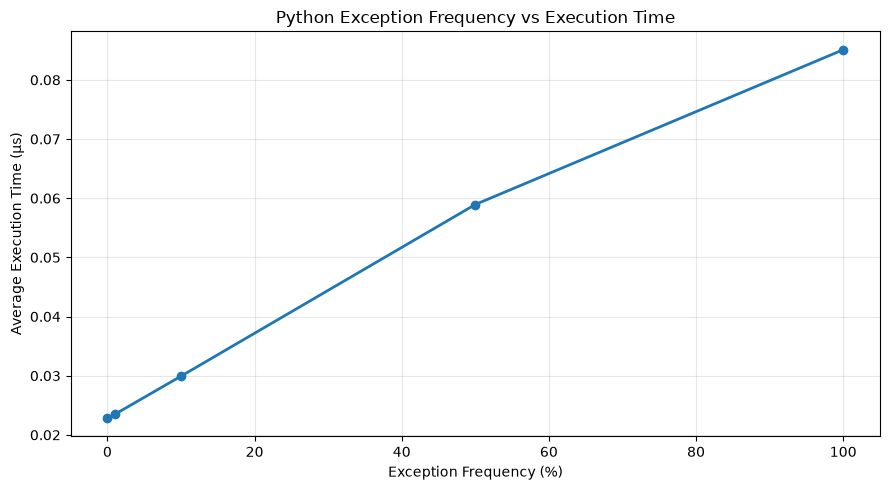

In [9]:
# Import matplotlib for visualizing benchmark results
import matplotlib.pyplot as plt

# Extract failure rates and execution times
rates = [result[0] for result in frequency_results]
times = [result[1] for result in frequency_results]

# Create the performance chart
plt.figure(figsize=(9, 5))
plt.plot(
    rates,
    times,
    marker="o",
    linewidth=2,
)

# Configure the chart
plt.xlabel("Exception Frequency (%)")
plt.ylabel("Average Execution Time (µs)")
plt.title("Python Exception Frequency vs Execution Time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 🔍 What's Happening?

Python exceptions have different performance characteristics depending on whether an exception is actually raised.

### 1. Normal Execution

Code executes without entering an exception handler. This provides a useful baseline for comparing execution costs.

### 2. Successful Try/Except

When no exception occurs, Python continues through the normal execution path. Modern CPython versions, particularly Python 3.11 and later, use optimized exception-handling mechanisms that reduce overhead on successful execution paths. As a result, simply placing code inside a `try/except` block does not necessarily introduce a significant performance penalty.

### 3. Raising an Exception

When an exception is raised, Python performs additional work. This includes managing the exception object, transferring execution to the matching handler, and maintaining exception-related state. Consequently, raising and catching an exception generally costs more than executing an equivalent successful operation.

### 4. Exception Frequency

When exceptions occur rarely, their total performance impact may be relatively small. As exceptions become more frequent, the additional work can increase the average execution time. However, the exact relationship depends on the workload, Python version, exception type, and runtime environment.

---

## 💡 Key Findings

- Successful `try/except` blocks can have very little overhead on modern CPython versions.
- Raising and catching an exception generally costs more than normal execution.
- Exception-heavy workloads can become slower as the frequency of raised exceptions increases.
- The actual performance difference depends on the Python version, implementation, hardware, and workload.
- Exceptions remain valuable for handling unexpected conditions and communicating errors.
- For frequently expected outcomes, ordinary conditional checks may be more appropriate, depending on the operation and its failure rate.

---

## 🧾 Conclusion

Python exceptions are not inherently expensive simply because a `try/except` block exists.

On modern CPython versions, successful exception-handling paths can execute with minimal additional overhead. The more significant cost usually appears when exceptions are actually raised and caught.

Our experiments demonstrate how exception frequency can influence execution time and why exceptions are generally better suited for exceptional conditions rather than routine control flow.

However, performance should not be the only consideration. Exceptions are an important part of writing clear, reliable Python applications.

The key lesson is simple: **Use exceptions when they express the correct behaviour, and benchmark before optimising exception-heavy code.**

---